<a href="https://colab.research.google.com/github/leman973/Deep-Learning/blob/main/Pract_1_DL_clg.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [46]:
import numpy as np

In [47]:
import pandas as pd
import tensorflow as tf

In [48]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Input

In [49]:
train_df = pd.read_csv("sign_mnist_train.csv")
test_df = pd.read_csv("sign_mnist_test.csv")

In [50]:
y_train = train_df["label"].values
x_train = train_df.drop("label",axis=1).values

In [51]:
y_test = test_df["label"].values
x_test = test_df.drop("label",axis = 1).values

In [52]:
x_train

array([[107, 118, 127, ..., 204, 203, 202],
       [155, 157, 156, ..., 103, 135, 149],
       [187, 188, 188, ..., 195, 194, 195],
       ...,
       [174, 174, 174, ..., 202, 200, 200],
       [177, 181, 184, ...,  64,  87,  93],
       [179, 180, 180, ..., 205, 209, 215]], shape=(27455, 784))

In [53]:
x_train = x_train.reshape(-1,28,28)
x_test = x_test.reshape(-1,28,28)

In [54]:
x_train

array([[[107, 118, 127, ..., 170, 170, 169],
        [111, 121, 129, ..., 171, 171, 170],
        [113, 123, 131, ..., 171, 171, 171],
        ...,
        [142, 150, 159, ..., 202, 201, 200],
        [142, 151, 160, ..., 204, 203, 202],
        [142, 151, 160, ..., 204, 203, 202]],

       [[155, 157, 156, ..., 138,  92, 108],
        [158, 159, 159, ..., 142, 116, 143],
        [161, 161, 161, ..., 147, 125, 140],
        ...,
        [162, 159, 145, ...,  91, 101,  94],
        [153, 139, 115, ...,  97,  95, 120],
        [135, 116,  95, ..., 103, 135, 149]],

       [[187, 188, 188, ...,  66,  77,  83],
        [188, 189, 189, ...,  73,  73,  71],
        [190, 190, 190, ...,  74,  68,  61],
        ...,
        [212, 198, 175, ..., 195, 193, 192],
        [202, 179, 152, ..., 195, 194, 193],
        [198, 166, 132, ..., 195, 194, 195]],

       ...,

       [[174, 174, 174, ..., 160, 158, 156],
        [178, 178, 177, ..., 162, 160, 158],
        [181, 180, 180, ..., 164, 162, 161

In [55]:
x_train = x_train / 255.0
x_test = x_test / 255.0

In [56]:
x_train

array([[[0.41960784, 0.4627451 , 0.49803922, ..., 0.66666667,
         0.66666667, 0.6627451 ],
        [0.43529412, 0.4745098 , 0.50588235, ..., 0.67058824,
         0.67058824, 0.66666667],
        [0.44313725, 0.48235294, 0.51372549, ..., 0.67058824,
         0.67058824, 0.67058824],
        ...,
        [0.55686275, 0.58823529, 0.62352941, ..., 0.79215686,
         0.78823529, 0.78431373],
        [0.55686275, 0.59215686, 0.62745098, ..., 0.8       ,
         0.79607843, 0.79215686],
        [0.55686275, 0.59215686, 0.62745098, ..., 0.8       ,
         0.79607843, 0.79215686]],

       [[0.60784314, 0.61568627, 0.61176471, ..., 0.54117647,
         0.36078431, 0.42352941],
        [0.61960784, 0.62352941, 0.62352941, ..., 0.55686275,
         0.45490196, 0.56078431],
        [0.63137255, 0.63137255, 0.63137255, ..., 0.57647059,
         0.49019608, 0.54901961],
        ...,
        [0.63529412, 0.62352941, 0.56862745, ..., 0.35686275,
         0.39607843, 0.36862745],
        [0.6

In [57]:
print("Training Data Shape", x_train.shape)

Training Data Shape (27455, 28, 28)


In [58]:
print("Testing Data Shape", x_test.shape)

Testing Data Shape (7172, 28, 28)


In [78]:
model = Sequential([
    Input(shape=(28,28)),
    Flatten(),
    Dense(128,activation="relu"),
    Dense(64,activation="relu"),
    Dense(25, activation="softmax")
])

In [79]:
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics = ["accuracy"])

In [80]:
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_5 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 25)             │         1,625 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,361 (431.10 KB)

 Trainable params: 110,361 (431.10 KB)

 Non-trainable params: 0 (0.00 B)

In [81]:
history = model.fit(
    x_train, y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/15
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.2871 - loss: 2.3619 - val_accuracy: 0.4639 - val_loss: 1.6675
Epoch 2/15
387/387 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5383 - loss: 1.4574 - val_accuracy: 0.5688 - val_loss: 1.3179
Epoch 3/15
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6234 - loss: 1.1609 - val_accuracy: 0.6628 - val_loss: 1.0532
Epoch 4/15
387/387 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6996 - loss: 0.9466 - val_accuracy: 0.6908 - val_loss: 0.9097
Epoch 5/15
387/387 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7417 - loss: 0.8094 - val_accuracy: 0.7844 - val_loss: 0.6897
Epoch 6/15
387/387 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7817 - loss: 0.6907 - val_accuracy: 0.7902 - val_loss: 0.6402
Epoch 7/15
387/387 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8176 - loss: 0.5834 - val_accuracy: 0.8234 - val_loss: 0.5240
Epoch 8/15
387/387 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8475 - loss: 0.4934 - val_accuracy: 0.

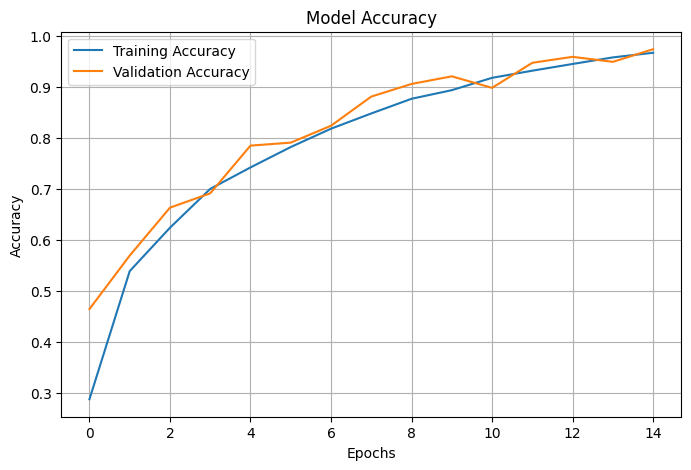

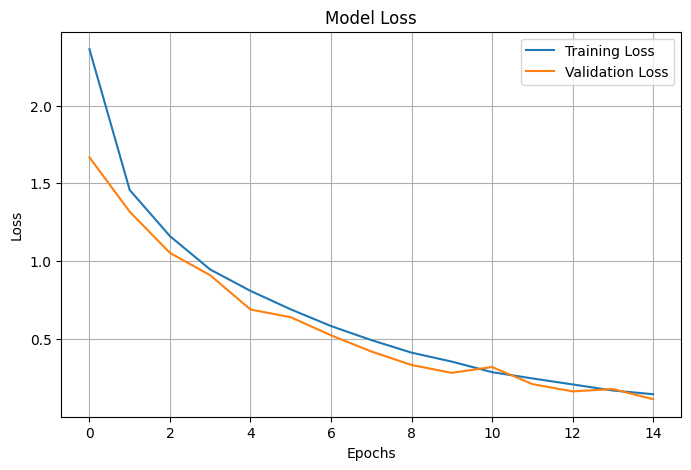

In [82]:
import matplotlib.pyplot as plt

# Accuracy graph
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()


# Loss graph
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

In [83]:
test_loss, test_acc = model.evaluate(x_test,y_test)

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7161 - loss: 1.2664


In [85]:
history.history["accuracy"]

0.9173175692558289

In [86]:
train_loss, train_accuracy = model.evaluate(x_train, y_train)

858/858 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9780 - loss: 0.1103
